# EN3160 - Assignment 02
## Fitting and Alignment

**Name:** Hiruna Yohan Wanniya Bandara  
**Index Number:** 230074J  
**GitHub:** 

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from skimage.feature import blob_log

## Question 1 - Blob Detection

Number of blobs: 129
Sigma range: 1.5 to 10


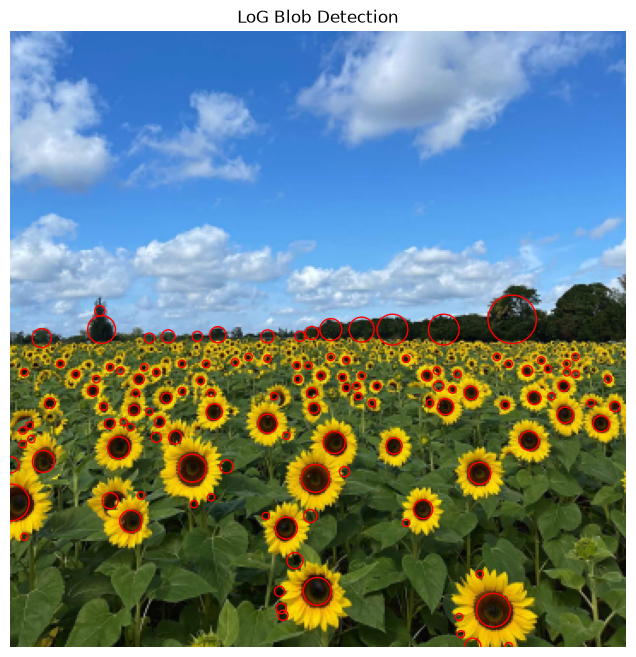

Largest detected circles:
1: center=(293.0, 168.0), sigma=10.00, radius=14.14
2: center=(0.0, 275.0), sigma=7.57, radius=10.71
3: center=(282.0, 338.0), sigma=6.96, radius=9.85
4: center=(223.0, 174.0), sigma=6.36, radius=8.99
5: center=(253.0, 174.0), sigma=6.36, radius=8.99
6: center=(106.0, 255.0), sigma=5.75, radius=8.13
7: center=(178.0, 261.0), sigma=5.75, radius=8.13
8: center=(179.0, 327.0), sigma=5.75, radius=8.13
9: center=(53.0, 174.0), sigma=5.75, radius=8.13
10: center=(205.0, 174.0), sigma=5.14, radius=7.27


In [9]:
image_path = "a2images/the_berry_farms_sunflower_field.jpeg"

im = cv.imread(image_path, cv.IMREAD_REDUCED_COLOR_4)

gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
gray = gray.astype(np.float32) / 255.0

gray_inv = 1 - gray

min_sigma = 1.5
max_sigma = 10
num_sigma = 15

blobs = blob_log(
    gray_inv,
    min_sigma=min_sigma,
    max_sigma=max_sigma,
    num_sigma=num_sigma,
    threshold=0.20,
    overlap=0.5
)

h = im.shape[0]
blobs = [b for b in blobs if b[0] > 0.45 * h]


blobs = np.array(blobs)

if len(blobs) > 0:
    blobs[:, 2] = blobs[:, 2] * np.sqrt(2)

print("Number of blobs:", len(blobs))
print("Sigma range:", min_sigma, "to", max_sigma)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))

for y, x, r in blobs:
    circle = plt.Circle(
        (x, y),
        r,
        fill=False,
        linewidth=1,
        color="red"
    )
    ax.add_patch(circle)

ax.set_title("LoG Blob Detection")
ax.axis("off")

plt.show()


largest = sorted(blobs, key=lambda x: x[2], reverse=True)

print("Largest detected circles:")

for i, (y, x, r) in enumerate(largest[:10]):
    sigma = r / np.sqrt(2)

    print(
        f"{i+1}: center=({x:.1f}, {y:.1f}), "
        f"sigma={sigma:.2f}, radius={r:.2f}"
    )

### Observation

The sunflower centers are dark, so I inverted the grayscale image before applying LoG.
For a LoG blob, the approximate radius is:
r = sqrt{2} *sigma
The sigma range used was 1.5 to 10.

The larger circles are mainly detected on the sunflowers closer to the camera. Smaller circles are found on the flowers further away.
A few incorrect blobs can also occur because other image regions may have a similar dark circular pattern.

## Question 2 - Line and Circle Fitting

Line inliers: 40
Best-fit line: a = 0.717, b = 0.697, d = 1.445
Circle inliers: 48
Best-fit circle center = (1.933, 3.108)
Best-fit circle radius = 9.848


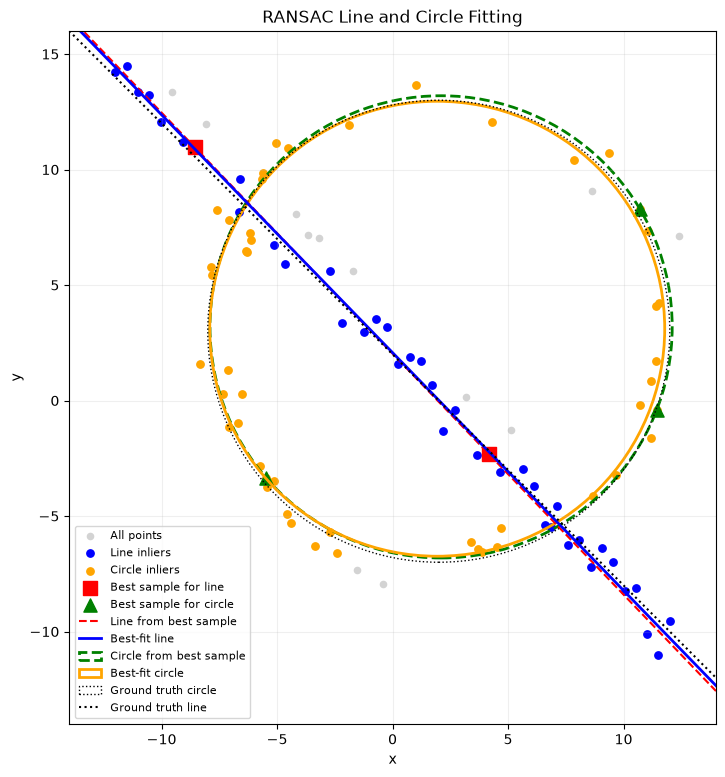

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Generate the noisy point set given in the assignment
np.random.seed(0)
N = 100
half_n = N // 2

r = 10
x0_gt, y0_gt = 2, 3
s = r / 16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s * np.random.randn(half_n)
x = x0_gt + (r+n)*np.cos(t)
y = y0_gt + (r+n)*np.sin(t)
X_circ = np.column_stack((x, y))

s = 1.0
m, c = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + c + s*np.random.randn(half_n)
X_line = np.column_stack((x, y))

X = np.vstack((X_circ, X_line))


#2(a) RANSAC line fitting
line_threshold = 0.75
line_iterations = 2000
best_line_count = 0

for i in range(line_iterations):
    ids = np.random.choice(len(X), 2, replace=False)
    p1, p2 = X[ids]

    v = p2 - p1
    length = np.linalg.norm(v)
    if length == 0:
        continue

    a, b = v[1]/length, -v[0]/length       # unit normal
    d = a*p1[0] + b*p1[1]

    distances = np.abs(a*X[:,0] + b*X[:,1] - d)
    inliers = distances < line_threshold
    count = np.sum(inliers)

    if count > best_line_count:
        best_line_count = count
        best_line_inliers = inliers
        best_line_sample = ids
        best_sample_line = (a, b, d)


line_points = X[best_line_inliers]
centroid = np.mean(line_points, axis=0)
_, _, Vt = np.linalg.svd(line_points - centroid)
normal = Vt[-1] / np.linalg.norm(Vt[-1])
a_fit, b_fit = normal
d_fit = np.dot(normal, centroid)


#2(b) Remove line and fit circle using RANSAC
X_remain = X[~best_line_inliers]

def circle_from_3_points(p1, p2, p3):
    A = np.array([[2*(p2[0]-p1[0]), 2*(p2[1]-p1[1])],
                  [2*(p3[0]-p1[0]), 2*(p3[1]-p1[1])]])

    B = np.array([p2[0]**2+p2[1]**2-p1[0]**2-p1[1]**2,
                  p3[0]**2+p3[1]**2-p1[0]**2-p1[1]**2])

    if abs(np.linalg.det(A)) < 1e-10:
        return None

    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(p1-center)
    return center[0], center[1], radius


circle_threshold = 1.0
circle_iterations = 3000
best_circle_count = 0

for i in range(circle_iterations):
    ids = np.random.choice(len(X_remain), 3, replace=False)
    circle = circle_from_3_points(*X_remain[ids])

    if circle is None:
        continue

    cx, cy, radius = circle
    distances = np.sqrt((X_remain[:,0]-cx)**2 + (X_remain[:,1]-cy)**2)
    errors = np.abs(distances-radius)

    inliers = errors < circle_threshold
    count = np.sum(inliers)

    if count > best_circle_count:
        best_circle_count = count
        best_circle_inliers = inliers
        best_circle_sample = ids
        best_sample_circle = circle


circle_points = X_remain[best_circle_inliers]

def circle_error(params):
    cx, cy, radius = params
    distances = np.sqrt((circle_points[:,0]-cx)**2 + (circle_points[:,1]-cy)**2)
    return np.sum((distances-radius)**2)

result = minimize(circle_error, best_sample_circle)
cx_fit, cy_fit, r_fit = result.x

print("Line inliers:", best_line_count)
print(f"Best-fit line: a = {a_fit:.3f}, b = {b_fit:.3f}, d = {d_fit:.3f}")
print("Circle inliers:", best_circle_count)
print(f"Best-fit circle center = ({cx_fit:.3f}, {cy_fit:.3f})")
print(f"Best-fit circle radius = {r_fit:.3f}")


#2(c)plotting 
fig, ax = plt.subplots(figsize=(9,9))

ax.scatter(X[:,0], X[:,1], s=20, color='lightgray', label='All points')
ax.scatter(X[best_line_inliers,0], X[best_line_inliers,1], s=28, color='blue', label='Line inliers')
ax.scatter(X_remain[best_circle_inliers,0], X_remain[best_circle_inliers,1], s=28, color='orange', label='Circle inliers')

line_sample_points = X[best_line_sample]
circle_sample_points = X_remain[best_circle_sample]

ax.scatter(line_sample_points[:,0], line_sample_points[:,1], marker='s', s=90, color='red', label='Best sample for line')
ax.scatter(circle_sample_points[:,0], circle_sample_points[:,1], marker='^', s=90, color='green', label='Best sample for circle')

x_plot = np.linspace(-14, 14, 300)

a_s, b_s, d_s = best_sample_line
ax.plot(x_plot, (d_s-a_s*x_plot)/b_s, '--', color='red', label='Line from best sample')
ax.plot(x_plot, (d_fit-a_fit*x_plot)/b_fit, color='blue', linewidth=2, label='Best-fit line')

cx_s, cy_s, r_s = best_sample_circle
ax.add_patch(plt.Circle((cx_s,cy_s), r_s, fill=False, linestyle='--', color='green', linewidth=2, label='Circle from best sample'))
ax.add_patch(plt.Circle((cx_fit,cy_fit), r_fit, fill=False, color='orange', linewidth=2, label='Best-fit circle'))

ax.add_patch(plt.Circle((x0_gt,y0_gt), r, fill=False, linestyle=':', color='black', label='Ground truth circle'))
ax.plot(x_plot, m*x_plot+c, ':', color='black', label='Ground truth line')

ax.set_xlim(-14,14)
ax.set_ylim(-14,16)
ax.set_aspect('equal')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('RANSAC Line and Circle Fitting')
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.show()


### 2(d) What happens if the circle is fitted first?

If the circle is fitted first, some points belonging to the line may also be accepted as circle inliers. This can produce an incorrect circle or reduce the accuracy of the estimated circle.

Fitting the line first and removing its consensus reduces this interference and makes the subsequent circle estimation more reliable.

## Question 3 - Image Superimposition using Homography

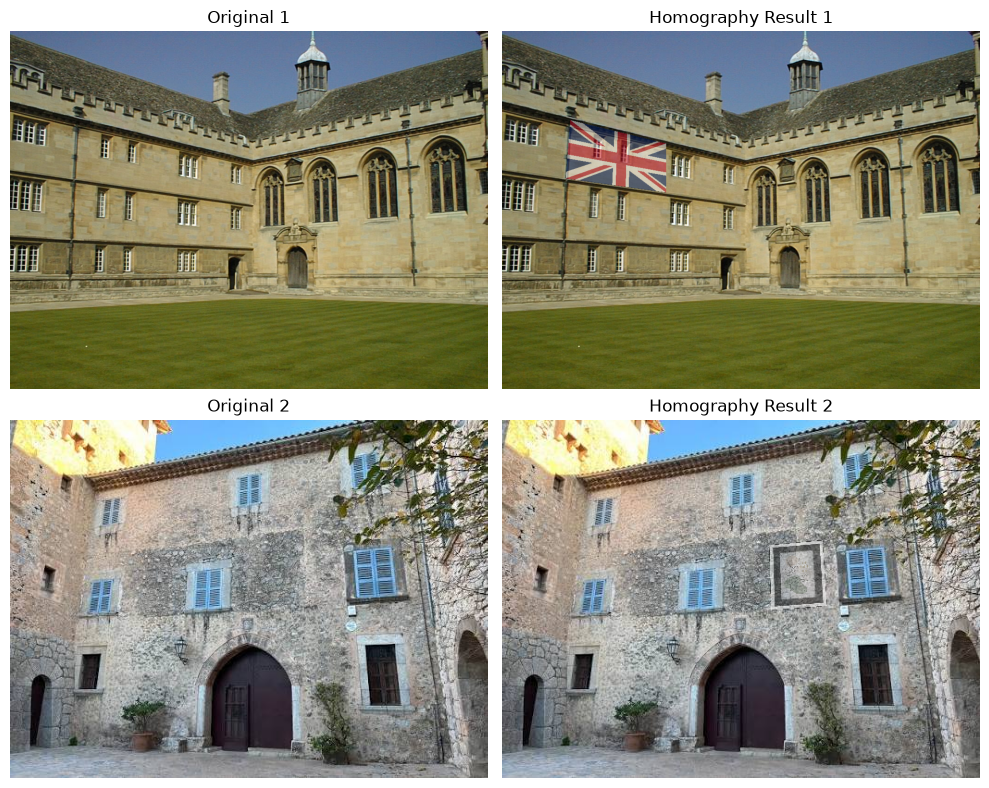

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


background = cv.imread("a2images/wadham.jpg")
flag = cv.imread("a2images/flag.png")

background_rgb = cv.cvtColor(background, cv.COLOR_BGR2RGB)

h, w = flag.shape[:2]

src_points = np.float32([
    [0, 0],
    [w-1, 0],
    [w-1, h-1],
    [0, h-1]
])

# Four points on the left wall
# Order: top-left, top-right, bottom-right, bottom-left
dst_points = np.float32([
    [145, 190],
    [350, 240],
    [350, 345],
    [135, 315]
])

# Calculate homography
H = cv.getPerspectiveTransform(src_points, dst_points)

# Warp the flag
warped_flag = cv.warpPerspective(
    flag,
    H,
    (background.shape[1], background.shape[0])
)

# Create mask
mask = np.zeros(background.shape[:2], dtype=np.uint8)

cv.fillConvexPoly(
    mask,
    dst_points.astype(int),
    255
)

# Put warped flag on background
result = background.copy()
# result[mask == 255] = warped_flag[mask == 255]
result[mask == 255] = (0.5 * warped_flag[mask == 255] +0.5 * background[mask == 255]).astype(np.uint8)

# Show original and result
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(background_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title("Flag Superimposed using Homography")
plt.axis("off")

plt.show()

print("Homography Matrix:")
print(H)






### Result and Discussion

The result shows that a rectangular image can be realistically placed on a surface viewed from a different perspective without manually changing its shape.

For the final experiment, the same method is applied to another image pair of my own choice. Planar surfaces are selected because they provide four clear corner points and allow the inserted image to appear naturally after perspective transformation.